# 중마시장 | 독립 근린형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, PURPOSE, CASE_COMPARISONS, PURPOSE_FIGURES, TIME_FIGURES,
                      plot_case_comparison, plot_purpose, plot_time_weekday)
CASE = '중마시장'


## 방문·체류 목적

,도착 OD,체류 STAY
귀가,62.4,77.7
업무,5.5,6.0
학업,1.5,0.9
쇼핑여가,0.8,0.7
기타,27.9,11.6
여행,1.9,3.1


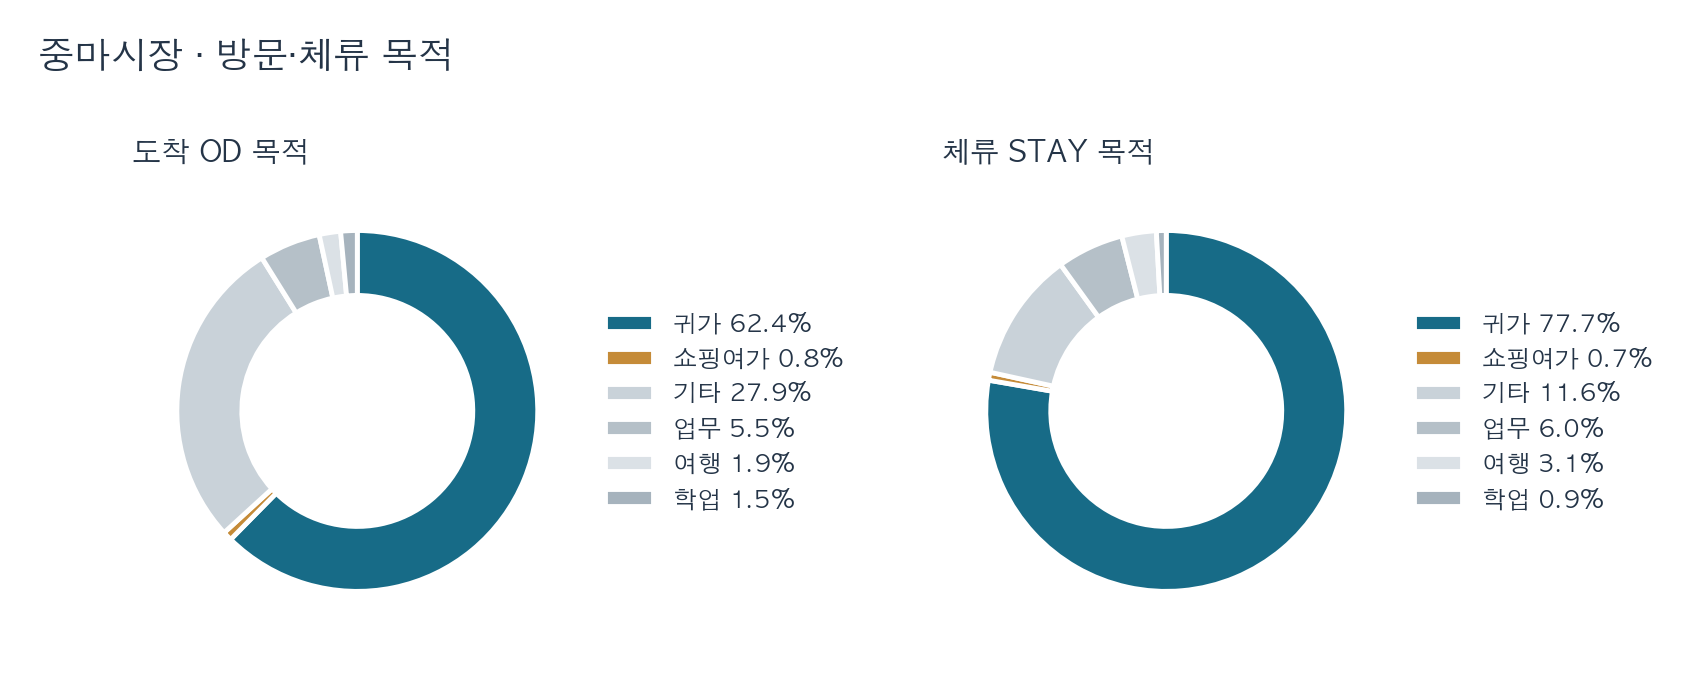

In [2]:
display((pd.DataFrame(PURPOSE[CASE]) * 100).round(1))
plot_purpose(CASE)
display(Image(filename=str(FIGS / PURPOSE_FIGURES[CASE][0])))

## 거리·접근

* 그림: 비공개 시장 위치와 행정동 경계로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 시장 위치 입력이 없어 저장된 그림을 표시합니다.


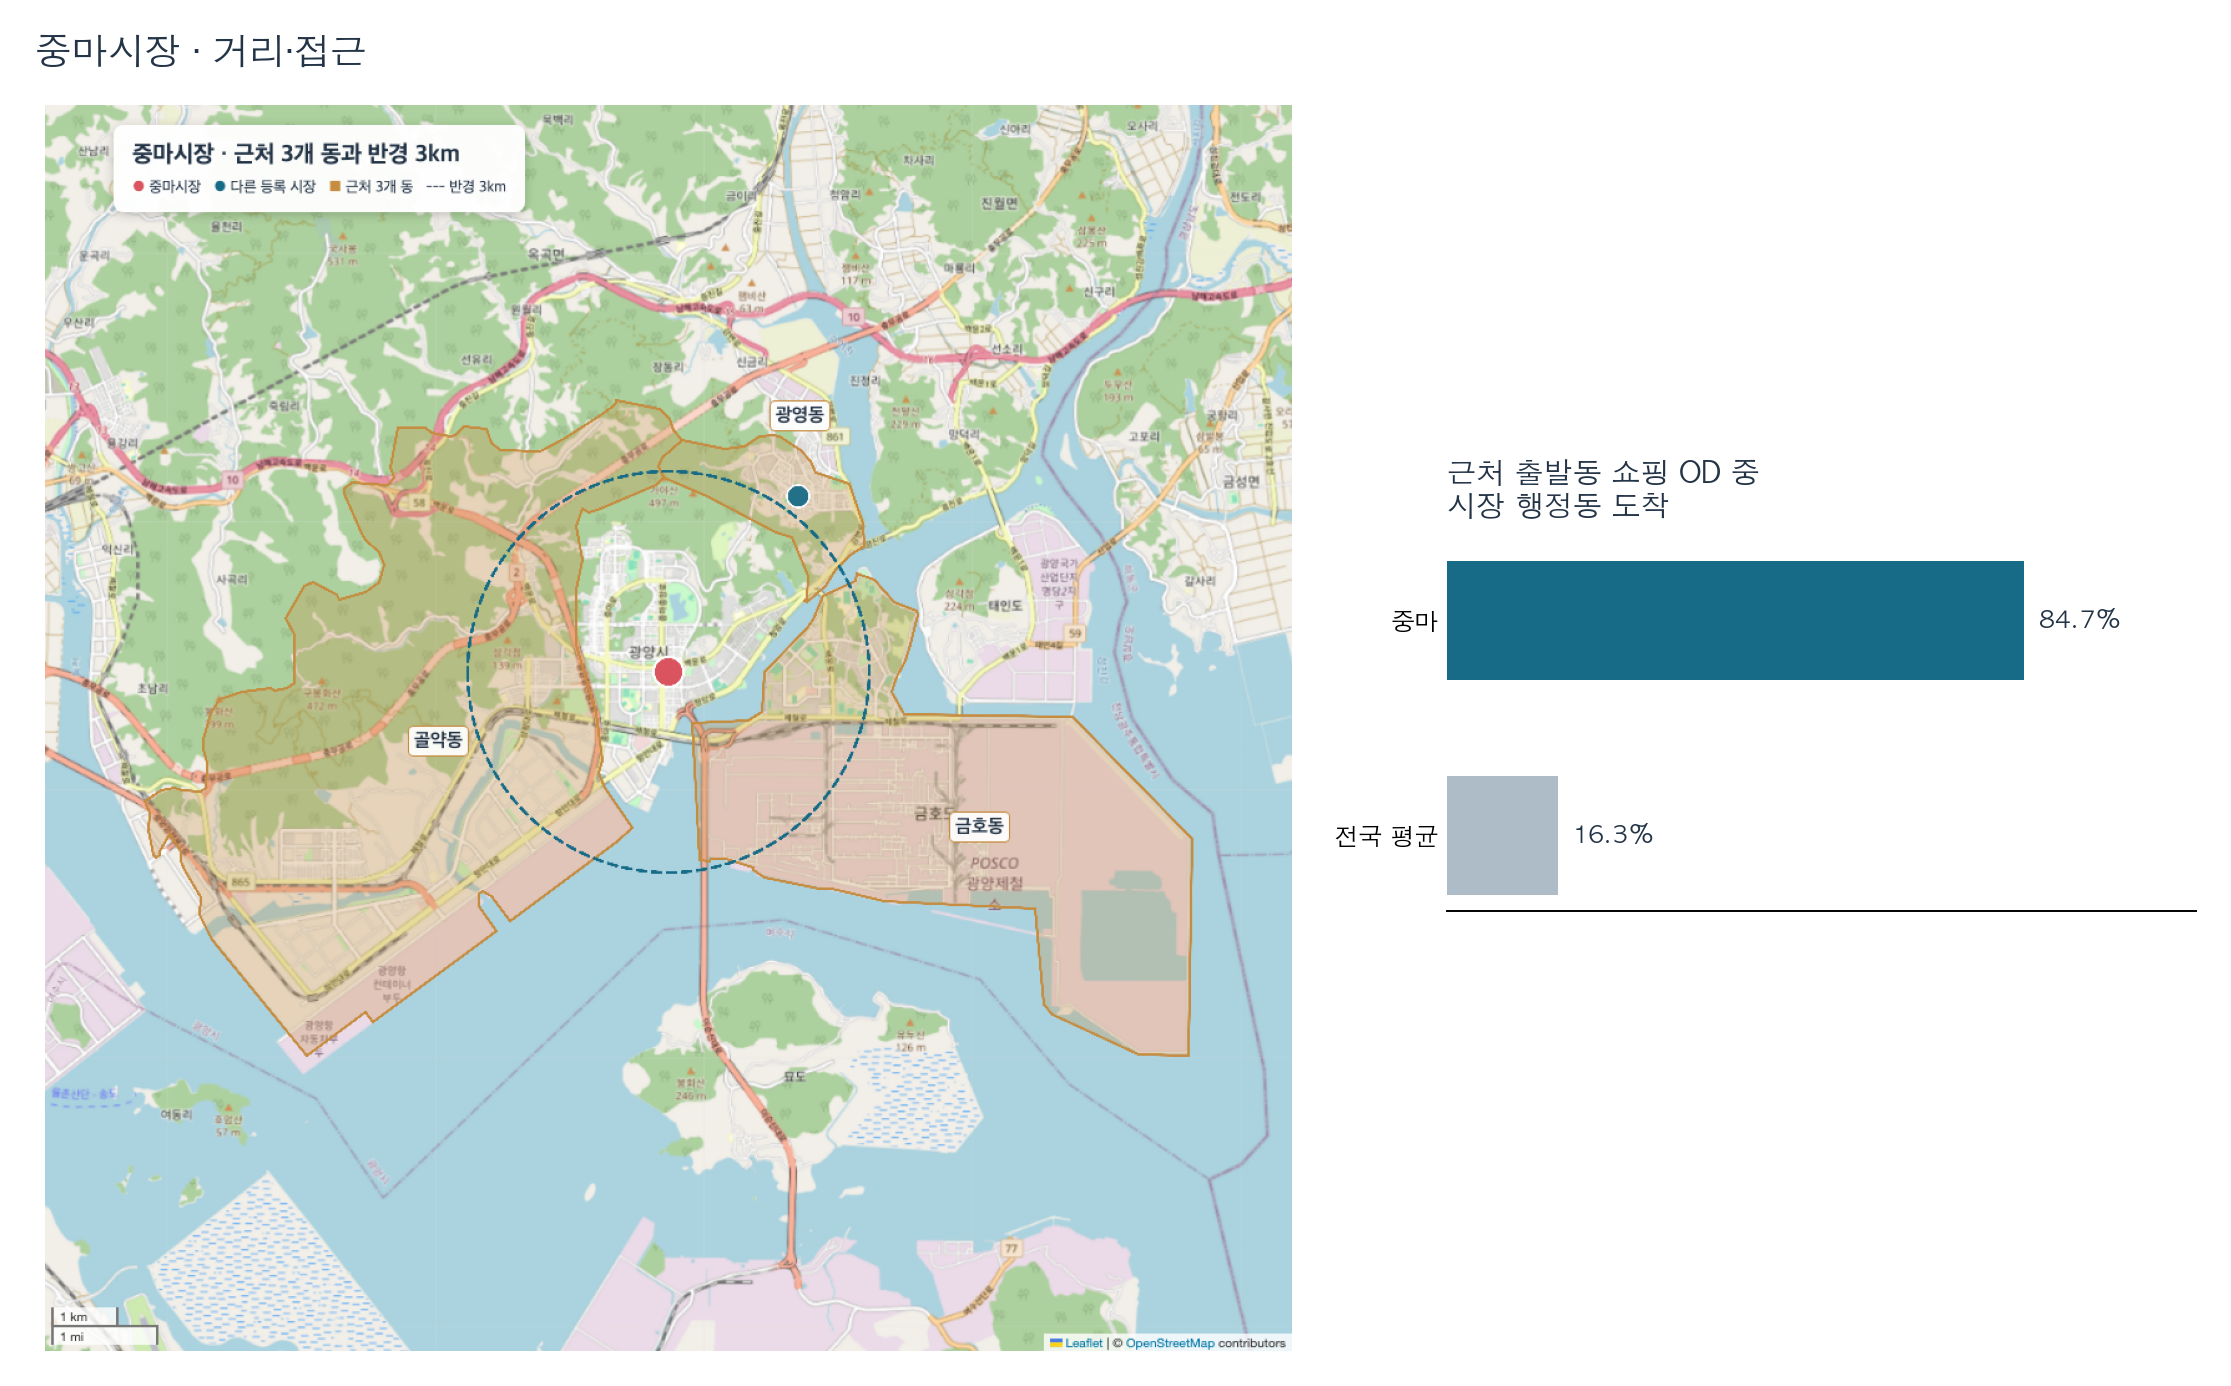

In [3]:
import os, json, tempfile
from plotting import jungma, render_map_png, plot_jungma_nearby
source_paths = [os.environ.get(name) for name in
                ["BC_MARKET_FEATURES", "BC_HDONG_BOUNDARIES", "BC_HDONG_CENTROIDS"]]
if all(p and Path(p).exists() for p in source_paths):
    features = pd.read_csv(source_paths[0], dtype={"행정기관코드": str})
    boundaries = json.loads(Path(source_paths[1]).read_text())
    centroids = pd.read_csv(source_paths[2], dtype={"행정기관코드": str})
    with tempfile.TemporaryDirectory() as folder:
        map_html = jungma(features, boundaries, centroids, Path(folder))
        map_png = Path(folder) / "map.png"
        render_map_png(map_html, map_png, 1000, 1000)
        plot_jungma_nearby(map_png)
else:
    print("비공개 시장 위치 입력이 없어 저장된 그림을 표시합니다.")
display(Image(filename=str(FIGS / "fig_v4_2b_jungma_nearby.png")))

## 체류 구성

In [4]:
stay = STAY
selected = stay.loc[stay["case"].eq(CASE),
                    ["metric", "case_share", "national_market_row_mean", "scope"]].copy()
selected[["case_share", "national_market_row_mean"]] *= 100
display(selected.rename(columns={"case_share":"사례 (%)",
                                  "national_market_row_mean":"전국 시장 행 평균 (%)"}))

,metric,사례 (%),전국 시장 행 평균 (%),scope
0,귀가 목적 STAY,77.728411,65.037312,2023-09-01~2023-10-15 중 일반일 38일; 전목적 STAY 시간별 ...
1,쇼핑여가 목적 STAY,0.712607,3.727711,2023-09-01~2023-10-15 중 일반일 38일; 전목적 STAY 시간별 ...


## 요일·시간

,measure,daytype,정점 시각,시간별 구성비 (%)
129,쇼핑여가 목적 도착 OD,주말,18,23.3
137,쇼핑여가 목적 도착 OD,평일,14,31.9
153,쇼핑여가 목적 체류 STAY,주말,18,11.5
167,쇼핑여가 목적 체류 STAY,평일,18,11.1


,measure,day_of_week,요일별 구성비 (%),observed_days
35,쇼핑여가 목적 도착 OD,0,11.1,4
36,쇼핑여가 목적 도착 OD,1,16.2,5
37,쇼핑여가 목적 도착 OD,2,18.3,6
38,쇼핑여가 목적 도착 OD,3,18.8,5
39,쇼핑여가 목적 도착 OD,4,14.5,6
40,쇼핑여가 목적 도착 OD,5,11.4,6
41,쇼핑여가 목적 도착 OD,6,9.6,6
42,체류 STAY 전체,0,14.5,4
43,체류 STAY 전체,1,14.4,5
44,체류 STAY 전체,2,14.5,6


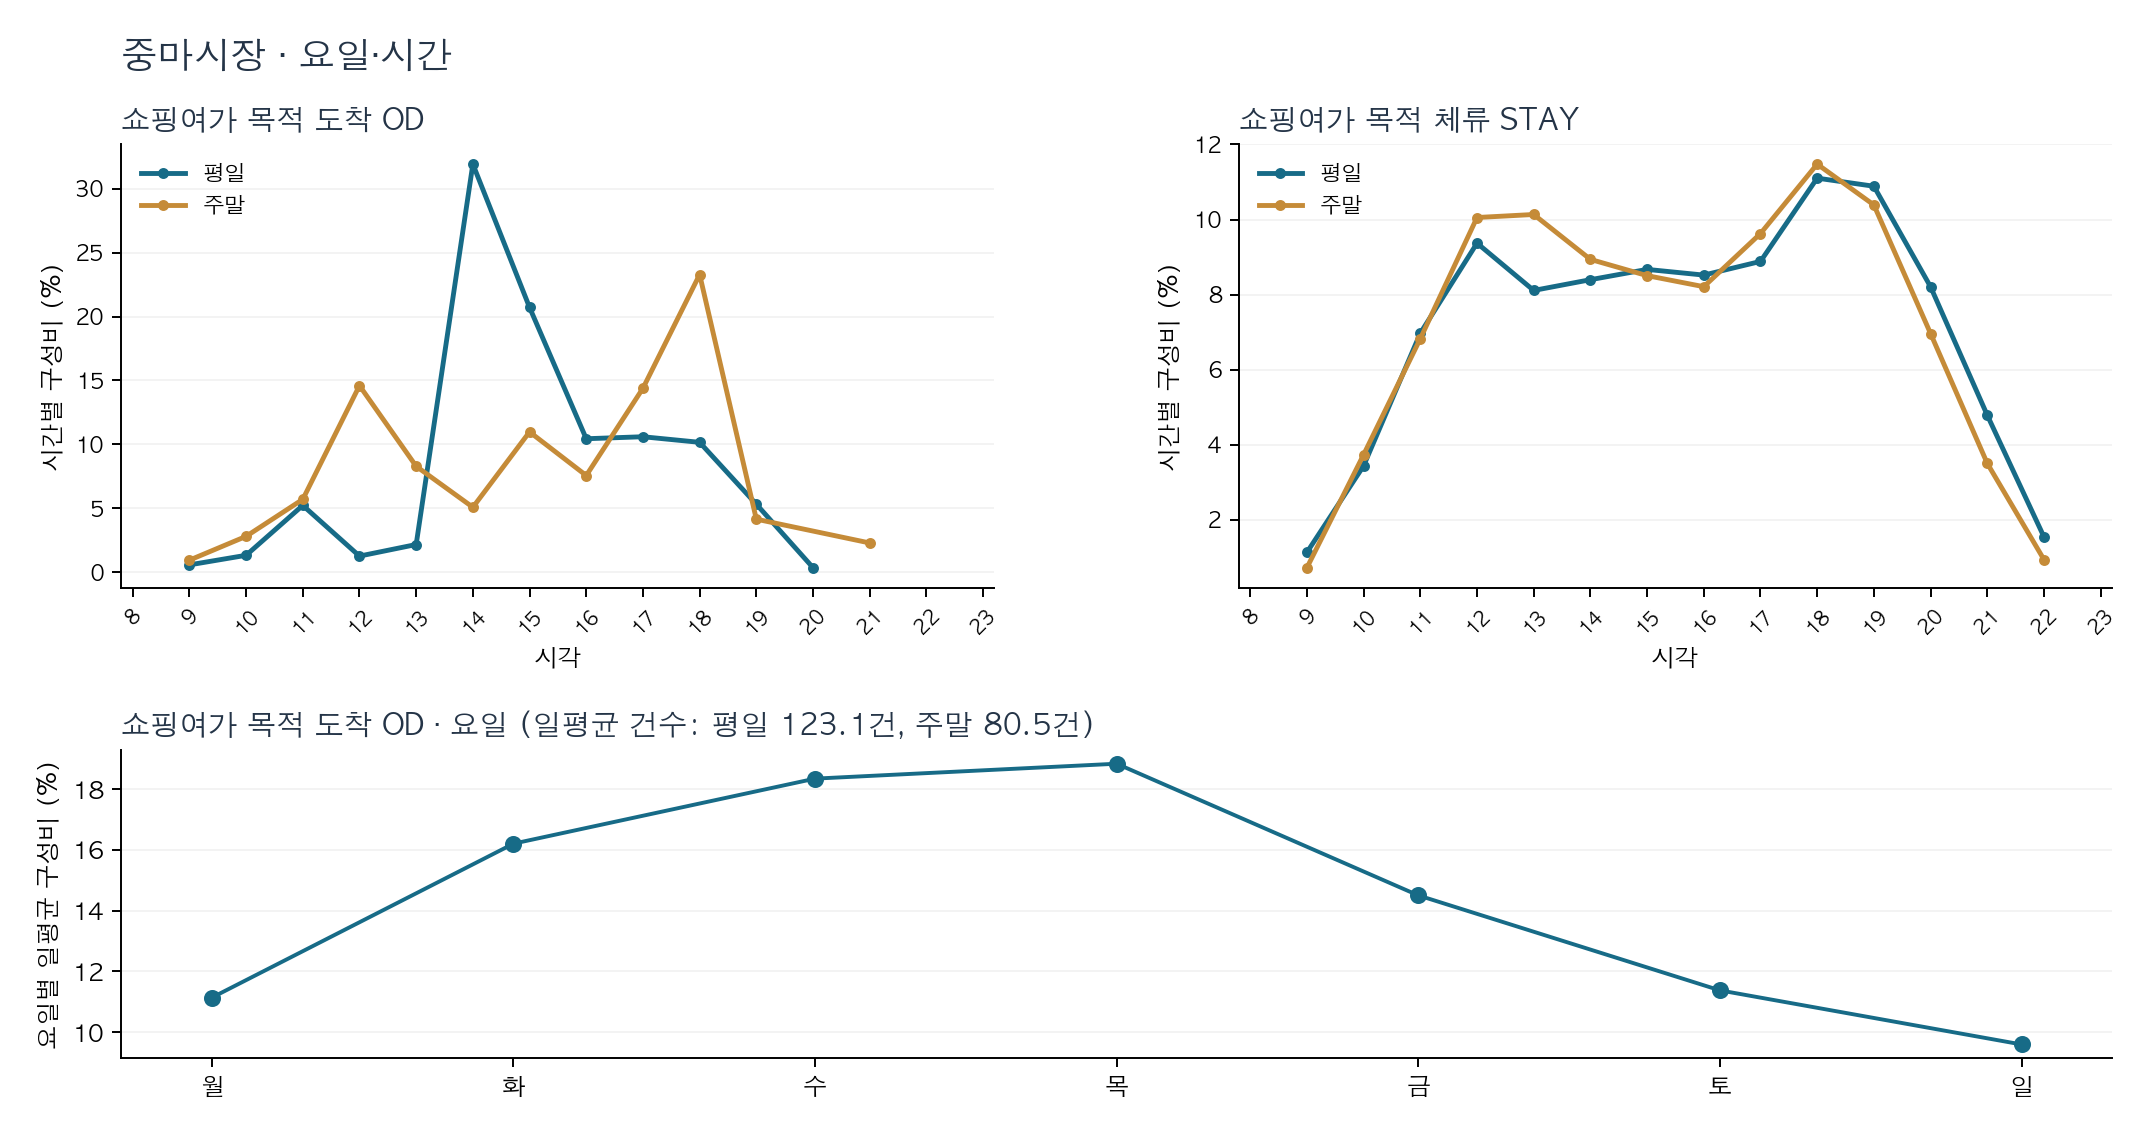

In [5]:
hourly = HOUR.loc[HOUR["case"].eq(CASE)].copy()
peaks = hourly.loc[hourly.groupby(["measure", "daytype"])["hour_share"].idxmax(),
                   ["measure", "daytype", "hour", "hour_share"]].copy()
peaks["hour_share"] = (peaks["hour_share"] * 100).round(1)
display(peaks.rename(columns={"hour":"정점 시각", "hour_share":"시간별 구성비 (%)"}))
weekday = WEEK.loc[WEEK["case"].eq(CASE)].copy()
weekday["요일별 구성비 (%)"] = weekday.groupby("measure")["daily_index"].transform(
    lambda values: values / values.sum() * 100
).round(1)
display(weekday[["measure", "day_of_week", "요일별 구성비 (%)", "observed_days"]])
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 제안

* 방안: 평일 14~19시 먹거리·휴게 공간을 시범 운영해 장보기 손님의 체류를 유도
* 상태: 시행·효과 미확인